# 02 — Modèle de sentiment (Spark MLlib)

Pipeline : `Tokenizer → StopWordsRemover → HashingTF → IDF → LogisticRegression`, entraîné sur **Sentiment140** (tweets labellisés positif / négatif).

In [1]:
import sys, json
sys.path.insert(0, "/home/jovyan/work")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from common import config

engine = create_engine(config.SQLALCHEMY_URL)
q = lambda sql: pd.read_sql(sql, engine)

# Palette : positif = bleu, négatif = orange (paire distinguable par les daltoniens)
COLORS = {"positive": "#2a78d6", "negative": "#eb6834"}
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "grid.color": "#e6e6e6", "axes.titleweight": "bold"})
FIG_DIR = config.OUTPUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()


## Métriques d'évaluation (jeu de test 20 %)

In [2]:
metrics = json.loads(config.METRICS_PATH.read_text())
print(f"Train : {metrics['train_rows']:,} lignes | Test : {metrics['test_rows']:,} | durée : {metrics['training_seconds']} s")
pd.DataFrame(metrics["results"]).set_index("model").round(4)

Train : 383,618 lignes | Test : 95,782 | durée : 113.4 s


,accuracy,f1,precision,recall,auc
model,,,,,
LogisticRegression,0.7632,0.7631,0.7636,0.7632,0.8336
NaiveBayes,0.7485,0.7485,0.7485,0.7485,0.8130


## Matrice de confusion

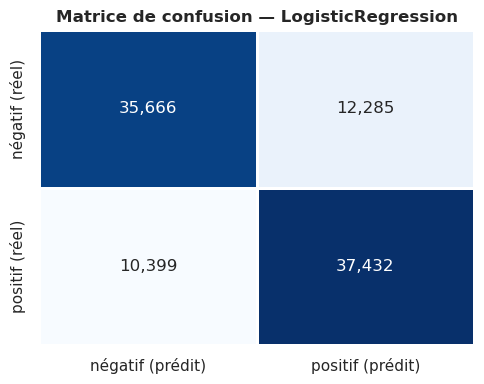

In [3]:
cm = pd.DataFrame(metrics["confusion_matrix"]).pivot(index="label", columns="prediction", values="count").fillna(0)
cm.index = ["négatif (réel)", "positif (réel)"]; cm.columns = ["négatif (prédit)", "positif (prédit)"]
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",.0f", cmap="Blues", cbar=False, linewidths=2, linecolor="white")
plt.title("Matrice de confusion — LogisticRegression")
savefig("confusion_matrix")

## Comparaison des modèles

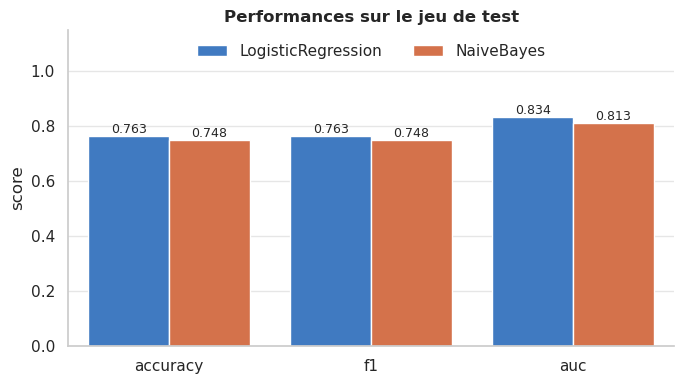

In [4]:
res = pd.DataFrame(metrics["results"]).melt(id_vars="model", value_vars=["accuracy", "f1", "auc"])
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=res, x="variable", y="value", hue="model", palette=["#2a78d6", "#eb6834"][: res.model.nunique()])
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=9)
plt.ylim(0, 1.15); plt.legend(loc="upper center", ncol=2, frameon=False); plt.xlabel(""); plt.ylabel("score"); plt.title("Performances sur le jeu de test")
savefig("model_comparison")

## Tester le modèle sur des phrases

In [5]:
from pyspark.ml import PipelineModel
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from common.text import clean_text

spark = config.get_spark("notebook-model", postgres=False, ui_port=4043)
model = PipelineModel.load(config.MODEL_PATH)
phrases = [
    "Just released my first open source project, so happy!",
    "The new update broke everything, terrible experience",
    "Mastodon is a really nice place to discuss tech",
    "I am tired of all these bugs",
]
df = spark.createDataFrame([(p,) for p in phrases], ["text"]).withColumn("clean_text", clean_text(F.col("text")))
(model.transform(df)
 .select("text", F.when(F.col("prediction") == 1, "positive").otherwise("negative").alias("sentiment"),
         F.round(vector_to_array("probability")[1], 3).alias("score_pos"))
 .toPandas())

,text,sentiment,score_pos
0,"Just released my first open source project, so...",positive,0.893
1,"The new update broke everything, terrible expe...",negative,0.064
2,Mastodon is a really nice place to discuss tech,positive,0.865
3,I am tired of all these bugs,negative,0.359


## Limites
- Domaine : modèle entraîné sur des tweets 2009, appliqué à des toots récents.
- Binaire : pas de classe *neutre* → les toots informatifs sont forcés en positif/négatif.
- Sac de mots : ne gère ni la négation complexe ni l'ironie.

In [ ]:
spark.stop()